# Code for training and evaluating (C)DVTINY model
(C)DVTINY stands for **(Comparative) DepthwiseVersatile for TINY-ML**

Copyright Radu DOGARU and IOANA DOGARU , July 2026   contact: radu.dogaru@upb.ro

Last updates - July 19, 2026; Sept. 2026, 11 Oct. 2026


This model expands research in [1], employing comparative synapses first proposed in [2], long before AdderNet [3] using Keras 3 framework (due to slow training, GPU/TPU support via Jax is recommended and supported) to a compact and low complexity DVTINY model.

[1] https://ieeexplore.ieee.org/document/9817267 published 2022

[2] https://ieeexplore.ieee.org/document/802828 published 1999

[3] https://ieeexplore.ieee.org/document/9156624 published 2020

Comparative layers are generated using Google's Gemini assistance and adapting some work from layers in https://github.com/uranusx86/AdderNet-on-tensorflow/blob/main/L1_layers.py  (L1-layers operates in both Tensorflow/Jax)

# 0 - INITS and UTILITY

#  0.1 - inits

In [1]:
# CELL 0.1
# Choice of backend and computing platform
#--------------------------------------------
import os
mediu_sw_calcul='jax' # "jax" sau "tensorflow" sau "torch"
# JAX is preferred;
# Use tensorflow only for classic synapses (multiplicative) allowing also .tflite conversion
# and MAC computations.

os.environ["KERAS_BACKEND"] = mediu_sw_calcul

import keras
import numpy as np
my_back=keras.config.backend()
print('Backend: ',my_back)
print('Keras version: ',keras.__version__)
if my_back=='tensorflow':
  import tensorflow as tf
  print('TF versiunea: ',tf.__version__)

import jax
my_device=(jax.devices()[0].platform).upper()
print('Actual computing platform: ',my_device)

Backend:  jax
Keras version:  3.13.2
Actual computing platform:  GPU


# 0.2 - Utilities

In [2]:
#
# Copyright Radu Dogaru, 1 June 2024
#
def truncate_float(float_number, decimal_places):
    multiplier = 10 ** decimal_places
    return int(float_number * multiplier) / multiplier

# Evaluates MAC & Accumulate - needs tensorflow backend and classic layers (not user-defined)
if my_back=='tensorflow':
  import tensorflow as tf
  from tensorflow.python.profiler import option_builder
  from tensorflow.python.profiler import model_analyzer

def get_flops(model):
    # [asistent Gemini, Google, apr. 2026]
    full_model = tf.function(lambda x: model(x))
    concrete_func = full_model.get_concrete_function(
        tf.TensorSpec([1] + list(model.input_shape[1:]), model.inputs[0].dtype)
    )

    opts = option_builder.ProfileOptionBuilder.float_operation()

    opts['output'] = 'none'
    # -----------------------------------
    # 3. Rulăm analiza
    graph_info = model_analyzer.profile(concrete_func.graph, options=opts)

    flops = graph_info.total_float_ops
    return flops

#-----------------------------------------------------------------------
# Datagen --> tensor conversion
# Copyright Radu Dogaru, 1 June 2024
# requires Tensorflow backend 
#------------------------------------------------------------
def conv_tensor(datagen, num_batches):
    for x_test, y_test in datagen:
            break;
    for b in range(num_batches-1):
        for x, y in datagen:
            break;
        x_test= tf.concat([x_test, x], axis=0)
        y_test= tf.concat([y_test, y], axis=0)
    return x_test, y_test

# Added May 30, 2026 - plays a sound when training is done
from IPython.display import Audio, display

def play_alert():
    framerate = 44100
    duration_seconds = 1.0  
    frequency_hz = 440.0    
    t = np.linspace(0, duration_seconds, int(framerate * duration_seconds))
    audio_data = np.sin(2 * np.pi * frequency_hz * t)
    display(Audio(audio_data, rate=framerate, autoplay=True))

# CUSTOM  COMPARATIVE LAYERS
Copyright Radu & Ioana Dogaru
L1 layers adapted from AdderNet layers in  https://github.com/uranusx86/AdderNet-on-tensorflow/blob/main/L1_layers.py
C Layers generated by us with Google's Gemini AI assistance

In [4]:
# Copyright Radu & Ioana Dogaru L1 layers adapted from 
# AdderNet layers in https://github.com/uranusx86/AdderNet-on-tensorflow/blob/main/L1_layers.py 
# C_Layers generated by us with Google's Gemini AI assistance and are JAX-optimized 
# ----------------------------------------------- version of June 2026 

import keras
from keras import layers
from keras import ops
#import keras.ops as ko
import jax

#============================== CONVOLUTIONAL Layers:  Depthwise &  Standard ===================================
# JAX backend needed
#---------------------------------------------------------------------------------------------------------------
@keras.saving.register_keras_serializable(package="CustomLayers")
class CDepthwiseConv2D(layers.Layer):
    def __init__(self, kernel_size, depth_multiplier=1, padding="SAME", strides=(1, 1), **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size if isinstance(kernel_size, (list, tuple)) else (kernel_size, kernel_size)
        self.depth_multiplier = depth_multiplier
        self.padding = padding.upper()
        self.strides = strides if isinstance(strides, (list, tuple)) else (strides, strides)

    def build(self, input_shape):
        input_channels = input_shape[-1]
        kernel_shape = (self.kernel_size[0], self.kernel_size[1], input_channels, self.depth_multiplier)

        self.w = self.add_weight(
            name="w",
            shape=kernel_shape,
            initializer= keras.initializers.RandomNormal(mean=0.0, stddev=0.5),
            #initializer="glorot_uniform",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        # 1. Obținem dimensiunile dinamice
        shape = ops.shape(inputs)
        batch_size, in_channels = shape[0], shape[3]
        kh, kw = self.kernel_size

        # 2. TRICUL PENTRU GPU (Eliminăm buclele 'for'):
        # Creăm o matrice identitate de dimensiune (kh * kw * in_channels, kh, kw, in_channels)
        # O vom folosi ca un "filtru-fantomă" în jax.lax.conv_general_dilated.
        # Acest filtru doar va colecta pixelii din vecinătate în canale, fără să-i modifice!
        num_patch_elements = kh * kw * in_channels
        eye_filter = jax.numpy.eye(num_patch_elements, dtype=inputs.dtype)
        # Reshaping în formatul de kernel JAX: (out_channels, in_channels, kh, kw)
        eye_filter = jax.numpy.reshape(eye_filter, (num_patch_elements, in_channels, kh, kw))

        # Transpunem inputul în formatul nativ JAX (NCHW) pentru viteză maximă pe GPU
        inputs_nchw = jax.numpy.transpose(inputs, (0, 3, 1, 2))

        # Mapăm padding-ul Keras în formatul JAX
        dn = jax.lax.ConvDimensionNumbers(lhs_spec=(0, 1, 2, 3), rhs_spec=(0, 1, 2, 3), out_spec=(0, 1, 2, 3))

        # Extragere ultra-rapidă de patch-uri la nivel de hardware GPU
        patches_nchw = jax.lax.conv_general_dilated(
            lhs=inputs_nchw,
            rhs=eye_filter,
            window_strides=self.strides,
            padding=self.padding,
            dimension_numbers=dn
        )

        # Readucem tensorul în formatul (Batch, Height, Width, kh * kw * in_channels)
        patches = jax.numpy.transpose(patches_nchw, (0, 2, 3, 1))
        out_h, out_w = patches.shape[1], patches.shape[2]

        # 3. Reshape pentru alinierea la Broadcasting (Batch, Out_H, Out_W, kh, kw, in_channels, 1)
        patches = jax.numpy.reshape(patches, (batch_size, out_h, out_w, kh, kw, in_channels))
        patches_expanded = ops.expand_dims(patches, axis=-1)

        # 4. Aliniem Weight-ul (W)
        w_expanded = ops.expand_dims(ops.expand_dims(ops.expand_dims(self.w, axis=0), axis=0), axis=0)

        # 5.  COMPARATIVE SYNAPSE (min of magnitudes, sign is the prodict of input and weight sign)
        # 5.1. Semn cu flux de gradient (STE)
        sign_inputs = patches_expanded + jax.lax.stop_gradient(ops.sign(patches_expanded) - patches_expanded)
        sign_w = w_expanded + jax.lax.stop_gradient(ops.sign(w_expanded) - w_expanded)

        # 5.Mag .clasic
        min_magnitude = ops.minimum(ops.absolute(patches_expanded), ops.absolute(w_expanded))

        # synaptic definition
        synaptic_activation = sign_inputs * sign_w * min_magnitude

        # Sumăm pe axele ferestrei (kh, kw)
        conv_output = ops.sum(synaptic_activation, axis=(3, 4))

        # 6. Combinăm canalele de intrare cu multiplier-ul pentru output-ul final Keras
        final_output = ops.reshape(conv_output, (batch_size, out_h, out_w, in_channels * self.depth_multiplier))
        return final_output

    def get_config(self):
        config = super().get_config()
        config.update({
            "kernel_size": self.kernel_size,
            "depth_multiplier": self.depth_multiplier,
            "padding": self.padding,
            "strides": self.strides,
        })
        return config


#=========================== Conv2D - L1  adapted for Keras3 and comparative instead of Adder Net 
#  from   https://github.com/uranusx86/AdderNet-on-tensorflow/blob/main/L1_layers.py
#------------------------------------------------------------------------------------------
@keras.saving.register_keras_serializable(package="CustomOps")
class L1Conv2D(layers.Layer):
    def __init__(self, kernel_size, strides=[1, 1], padding='SAME', dilated=1, comp=True, eps=2e-3, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size # Salvăm tuple-ul original pentru config
        #print('Kernel size: ',kernel_size)
        self.kernel_h, self.kernel_w, self.kernel_in_ch, self.kernel_out_ch = kernel_size

        self.strides = strides if isinstance(strides, (list, tuple)) else [strides, strides]
        self.dilated = dilated if isinstance(dilated, (list, tuple)) else [dilated, dilated]
        self.padding = padding
        self.comp = comp
        self.eps = eps

    def build(self, input_shape):
        if self.padding == 'SAME':
            pad_h, pad_w = (self.kernel_h - 1) // 2, (self.kernel_w - 1) // 2
        elif self.padding == 'VALID':
            pad_h, pad_w = 0, 0

        # Calculăm output shape pentru Reshape layer
        out_h = (input_shape[1] - self.kernel_h + 2 * (pad_h if self.padding == 'SAME' else 0)) // self.strides[0] + 1
        out_w = (input_shape[2] - self.kernel_w + 2 * (pad_w if self.padding == 'SAME' else 0)) // self.strides[1] + 1

        self.input_reshape = keras.layers.Reshape([out_h, out_w, self.kernel_h * self.kernel_w * self.kernel_in_ch, 1])
        self.kernel = self.add_weight(name='kernel', shape=(self.kernel_h, self.kernel_w, self.kernel_in_ch, self.kernel_out_ch), trainable=True)
        self.subtract_layer = keras.layers.Subtract()

    def _custom_gradient(self, forward, backward):
        return backward + ops.stop_gradient(forward - backward)

    def call(self, inputs):
        '''
        A trick from [Sergey Ioffe]()
        a op that behave as f(x) in forward mode,
        but as g(x) in the backward mode.
        '''
        # im2col  method 
        inputs_patches = ops.image.extract_patches(
            inputs,
            size=(self.kernel_h, self.kernel_w),
            strides=(self.strides[0], self.strides[1]),
            padding=self.padding
        )
        inputs_patches = self.input_reshape(inputs_patches)
        #print('Input patches shape:', inputs_patches.shape)
        kernel_reshape = ops.reshape(self.kernel, [1, 1, 1, self.kernel_h * self.kernel_w * self.kernel_in_ch, self.kernel_out_ch])

        if self.comp:   # Comparative versus Adder Net
            differ = self.subtract_layer([inputs_patches, kernel_reshape])
            sumare = self.subtract_layer([inputs_patches, -kernel_reshape])
            forward = ops.abs(sumare) - ops.abs(differ)  # Comparative synapse with L1 (not using min() - in TinyML deployment, trained model better uses min())
            backward = ops.sqrt(sumare**2 + self.eps) - ops.sqrt(differ**2 + self.eps)  # Optim
            
        else:
            differ = self.subtract_layer([inputs_patches, kernel_reshape])
            forward = -ops.abs(differ)   # AdderNet
            
            backward= - ops.sqrt(differ**2 + self.eps)
        return ops.sum(self._custom_gradient(forward, backward), axis=3)

    def get_config(self):
        config = super().get_config()
        config.update({
            "kernel_size": self.kernel_size,
            "strides": self.strides,
            "padding": self.padding,
            "dilated": self.dilated,
            "comp": self.comp,
            "eps": self.eps
        })
        return config

#============================== DENSE - comparativ and normal ========================================
#
#------------------------------------------------------------------------------------------------------
@keras.saving.register_keras_serializable(package="CustomLayers")
class CDense(layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        input_dim = input_shape[-1]

        # Avem nevoie de un singur tensor de greutăți acum
        self.w = self.add_weight(
            name="w",
            shape=(input_dim, self.units),
            initializer="glorot_uniform",
            #initializer= keras.initializers.RandomNormal(mean=0.0, stddev=0.5),   # Nu e deloc eficient
            trainable=True,
        )

        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        # 1. Expandăm dimensiunile pentru broadcasting pe forma (batch, input_dim, units)
        inputs_expanded = ops.expand_dims(inputs, axis=-1)  # (batch, input_dim, 1)
        w_expanded = ops.expand_dims(self.w, axis=0)        # (1, input_dim, units)

        # COMPARATIVE SYNAPSE (min-based)
        # 2. Extreagem semnele (polaritatea) pentru input și pentru singurul weight

        sign_inputs = inputs_expanded + jax.lax.stop_gradient(ops.sign(inputs_expanded) - inputs_expanded)
        sign_w = w_expanded + jax.lax.stop_gradient(ops.sign(w_expanded) - w_expanded)
        # 3. Calculăm magnitudinea minimă direct între intensitatea intrării și cea a sinapsei
        min_magnitude = ops.minimum(ops.absolute(inputs_expanded), ops.absolute(w_expanded))

        # 4. IMplement the comparative synapse
        synaptic_activation = sign_inputs * sign_w * min_magnitude

        # 5. Sumăm pe axa input_dim pentru a colecta răspunsul tuturor sinapselor din neuron
        output = ops.sum(synaptic_activation, axis=1) + self.bias

        if self.activation is not None:
            output = self.activation(output)

        return output

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "activation": keras.activations.serialize(self.activation),
        })
        return config

#=====================================================================================
# L1 DENSE (based on L1 - extension of AdderNet addpated from  https://github.com/uranusx86/AdderNet-on-tensorflow/blob/main/L1_layers.py )
#======================================================================================
@keras.saving.register_keras_serializable(package="CustomOps")
class L1Dense(layers.Layer):
    def __init__(self, out_dims, comp=True, eps=2e-1, **kwargs):
        super().__init__(**kwargs)
        self.out_dims = out_dims
        self.comp = comp
        self.eps = eps

    def build(self, input_shape):
        self.in_dims = input_shape[-1]
        self.kernel = self.add_weight(
            name='kernel', shape=(self.in_dims, self.out_dims),
            trainable=True,
            initializer="glorot_uniform",
            )
        self.subtract_layer = keras.layers.Subtract()
        self.input_reshape = keras.layers.Reshape([self.in_dims, 1])

    def _custom_gradient(self, forward, backward):
        return backward + ops.stop_gradient(forward - backward)

    def call(self, inputs):
        '''
        A trick from [Sergey Ioffe](http://stackoverflow.com/a/36480182)
        a op that behave as f(x) in forward mode,
        but as g(x) in the backward mode.
        '''
        inputs_reshape = self.input_reshape(inputs)
        kernel_reshape = ops.reshape(self.kernel, [1, self.in_dims, self.out_dims])

        if self.comp:
            differ = self.subtract_layer([inputs_reshape, kernel_reshape])
            sumare = self.subtract_layer([inputs_reshape, -kernel_reshape])
            forward = ops.abs(sumare) - ops.abs(differ)     # comparative nescalat  ()
            backward = ops.sqrt(sumare**2 + self.eps) - ops.sqrt(differ**2 + self.eps)  # surogate  - optimal for training
            
        else:
            # AdderNet only - in general AdderNet for the same structure performs poorly.
            differ = self.subtract_layer([inputs_reshape, kernel_reshape])
            forward = -ops.abs(differ)
            backward = -ops.sqrt(differ**2 + self.eps)
            

        return ops.sum(self._custom_gradient(forward, backward), axis=1)

    def get_config(self):
        config = super().get_config()
        config.update({
            "out_dims": self.out_dims,
            "comp": self.comp,
            "eps": self.eps
        })
        return config

# 1 - DATA SETS
Run either cell 1.1 (tensor) or 1.2. ("data_generator")

# 1.1 - Tensor data

In [ ]:
# run only for extra datasest
!pip install extra-keras-datasets
from extra_keras_datasets import svhn, usps

In [5]:
# CELULA 1.1 - date in format tensor import din Keras
# EMNIST - set de date in Kaggle
#-----------------------------------------------------------------------
from keras.datasets import mnist, cifar10, cifar100, fashion_mnist
from datasets import load_dataset
import numpy as np

datagen=False
out_coding='cat' # modul categorical ; poate si 'non'
in_coding='clast'  # canalele de intrare sunt in ordinea "channel-last " (pot fi si cfirst - de ex in Pytorch )
num_replici=8  # TPU Kaggle (1 in Colab)

test_exists=False
dataset='cifar10' # cifar10, cifar20, or cifar100, mnist or emnist or  f-mnist

if my_device=='TPU':
    batch_size=num_replici*64  #
else:
    batch_size=512
#reduced=0.1  #  a positive value represents a reduced number of training samples (when memory allocation problems occur)

if dataset=='mnist':
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
    
elif dataset=='svhn':
    (x_train, y_train), (x_test, y_test) = svhn.load_data()
    y_train-=1; y_test-=1;
    
elif  dataset[:5]=='cifar':
    # Hugging Face source
    if dataset[5:8]=='10':
        lind='label'
        datas = load_dataset("uoft-cs/cifar10")
    elif dataset[5:8]=='20':
        lind='fine_label'
        datas = load_dataset("uoft-cs/cifar100")
    elif dataset[5:8]=='100':
        lind='coarse_label'
        datas = load_dataset("uoft-cs/cifar100")
    # Extragere corectă (atenție la 'fine_label' în loc de 'label')
    x_train = np.array(datas['train']['img'])
    y_train = np.array(datas['train'][lind]) # Aici era diferența
    x_test = np.array(datas['test']['img'])
    y_test = np.array(datas['test'][lind])

    #(x_train, y_train), (x_test, y_test) = cifar10.load_data()  # slow / removed
    
elif dataset=='usps':
    (x_train, y_train), (x_test, y_test) = usps.load_data()
    
elif  dataset=='f-mnist':
    (x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
    
elif dataset=='emnist':
    # Avalable only when running on Kaggle
    # location https://www.kaggle.com/datasets/souhardyadas27/emnist
    # REPRESENTS 62-CLASSES "By-Class"
    x_train=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_x_train.npy')
    x_test=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_x_test.npy')
    y_train=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_y_train.npy')
    y_test=np.load('/kaggle/input/datasets/souhardyadas27/emnist/emnist_y_test.npy')
    
#--- scaling
if (np.ndim(x_train)==3):   # La seturile de date MNIST or F-MNIST

        x_train=np.reshape(x_train, [np.shape(x_train)[0],np.shape(x_train)[1],np.shape(x_train)[2], 1])
        x_test=np.reshape(x_test, [np.shape(x_test)[0],np.shape(x_test)[1],np.shape(x_test)[2], 1] )


'''
# shuffling samples - useful when using validation_split=0.2 in model.fit 
ix = np.arange(len(x_train))
np.random.seed(42)  # Opțional, pentru reproductibilitate
np.random.shuffle(ix)

x_train = x_train[ix]
y_train = y_train[ix]
'''

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /=255

#--------

num_classes=int(np.max(y_train)+1)
num_inputs = np.shape(x_test)[1]
input_shape=np.shape(x_train)[1:4]
imsize=input_shape[0]

# convert to categorical
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
Ntr=np.shape(x_train)[0]; Nva=np.shape(x_test)[0];  # util sa avem numar train / ts
print('Set date: ',dataset)
print('Esantioane antrenare: ',Ntr); print('Esantioane validare: ',Nva);
print('Numar clase : ',num_classes)
print('Input shape : ',input_shape)
print('Batch_size: ',batch_size)


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Set date:  cifar10
Esantioane antrenare:  50000
Esantioane validare:  10000
Numar clase :  10
Input shape :  (32, 32, 3)
Batch_size:  512


# 1.2a. Data from folders (examples based on Kaggle plaform)
- one can select image size, batch_size (training); sbatch_size (validation) + other

In [5]:
# 
# Copyright Radu and Ioana Dogaru, contact radu.dogaru@upb.ro 
# UNST Politehnica Bucuresti

import keras
import numpy as np
from keras.utils import image_dataset_from_directory as imdir
#-----------------------------------------------------------------------------
num_replici=8 # For Kaggle TPU (1 in Colab)
imsize = 48    # Image size
if my_device=='TPU':
    batch_size=4*num_replici; sbatch_size=8*num_replici;
else:
    batch_size=32; sbatch_size= 64
#
#
dataset='skin' # one particular example
# check that is allredy added in Kaggle
#-------------- dataset properties
datagen=True #

# SELECTING DATASET
if dataset=='br_tum':
    #location https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
    SPL=False   # SPL = split if there is no validation set (split factor 0.2)
                # False daca avem director separat pentru set validare
    train_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training'
    val_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'
    test_dir='/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing'
    test_exists=True
    N_test=1000  # Batch size for test generator

elif dataset == 'skin':   
    # location   (Kaggle dataset link) for "Add Input"
    SPL=True
    #val_dir=''
    train_dir='/kaggle/input/datasets/hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images/melanoma_cancer_dataset/train'
    test_dir='/kaggle/input/datasets/hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images/melanoma_cancer_dataset/test'
    test_exists=True
    N_test=1000    # batch size for test generator
# ... other sets may be added following the above examples 

# DEFINE DATAGENS
if SPL:
    train_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.2,
        subset='training',
        seed=34,
        image_size=(imsize, imsize))
    validation_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=sbatch_size,
        shuffle=True,
        validation_split=0.2,
        subset='validation',
        seed=34,
        image_size=(imsize, imsize))
else:
    train_generator = imdir(
        directory=train_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        image_size=(imsize, imsize))
    validation_generator = imdir(
        directory=val_dir,  # not splitting anymore 
        labels='inferred',
        label_mode='categorical',
        batch_size=sbatch_size,
        shuffle=True,
        image_size=(imsize, imsize))
if test_exists:
    test_generator = imdir(
        directory=test_dir,
        labels='inferred',
        label_mode='categorical',
        batch_size=N_test,  # may be as large as the entire set (exhuasted resorces may occur)
        shuffle=False,
        image_size=(imsize, imsize))
#-------------------------------------------------
num_classes=np.shape(train_generator.class_names)[0]


xt,yt=conv_tensor(train_generator, num_batches=1)
input_shape=(xt.shape[1], xt.shape[2], xt.shape[3])


if datagen:
    x_test, y_test= conv_tensor(datagen=validation_generator, num_batches=1)
print('max value in data: ',np.max(x_test))
if np.max(x_test)>128:
    print('Choose SCALE when define model hyperpars')
print('input shape: ', x_test.shape[1:4])  

print('num classes: ', num_classes, ' input shape : ', input_shape)
print('Class names: ',train_generator.class_names)  # un numar mai mic de clase

STEPS_PER_EPOCH = len(train_generator);


Found 9605 files belonging to 2 classes.
Using 7684 files for training.


2026-10-12 12:15:28.008876: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 9605 files belonging to 2 classes.
Using 1921 files for validation.
Found 1000 files belonging to 2 classes.
max value in data:  255.0
Choose SCALE when define model hyperpars
input shape:  (48, 48, 3)
num classes:  2  input shape :  (48, 48, 3)
Class names:  ['benign', 'malignant']


# 2 MODELS
- 2.1 - HVTINY (compact from )
- 2.2 - (C)DVTINY - novel

# 2.1. Model HVTINY - for TinyML
- details here: https://github.com/radu-dogaru/
includes particular hyperparam definition

In [6]:
# A tiny-oriented model instantiated from 
# github (more details and reprint there)
# https://github.com/radu-dogaru/hvtiny
import requests
url = "https://raw.githubusercontent.com/radu-dogaru/hvtiny/refs/heads/main/hvtiny_cat.py"
response = requests.get(url)
if response.status_code == 200:
    # Execute code 
    exec(response.text)
    # Call the function 
else:
    print("Download problem")

# Instantiete a particular model

version='HVTINY' # HVTINY model defined above
#
myflat=0; my_profil=(1, 4, 2); myk=28; mynl=(2,1); mydrp=0.3; myhid=False
lrate=0.02/batch_size
myact='relu'  # or 'hard_silu' (may increase accuracy but adds extra resources)
myscale=True  #  false if already scaled ; True elsewhere

model=hvtiny(input_shape, num_classes=num_classes, flat=myflat, hid=myhid, profil=my_profil, k=myk, nl=mynl, scale=myscale, drop=mydrp, lr=lrate)
if myscale==False:
    mys='N'
elif myscale==True:
    mys='S'
model_name=version+'_'+mys+'_'+str(myflat)+'_d:'+str(mydrp)+'_'+str(my_profil)+'_k:'+str(myk)+'_nl'+str(mynl)+'_hid:'+str(myhid)
print(model_name)
model.summary()

Profil:  (1, 4, 2)
adding
adding
HVTINY_S_0_d:0.3_(1, 4, 2)_k:28_nl(2, 1)_hid:False


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_1CLONE             │ (None, 48, 48, 3)      │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 28)     │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 48, 48, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 48, 48, 28)     │           280 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 48, 48, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 48, 48, 28)     │           280 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 24, 24, 112)    │         3,500 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 24, 112)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 24, 24, 112)    │         1,120 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 112)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 112)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 12, 12, 56)     │         7,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 56)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 56)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 56)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 56)             │           224 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 56)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           114 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 2)              │             

 Total params: 13,638 (53.27 KB)

 Trainable params: 13,526 (52.84 KB)

 Non-trainable params: 112 (448.00 B)

# Model DVTINY

In [121]:
# DVTiny CNN deffinition
# Low complexity yet accurate model - well suited for MCU-oriented TinyML apps.
# Copyright Radu DOGARU  radu.dogaru@upb.ro , june 2026

# Last updated July 11, 2026, 11 oct. 2026
#----------------------------------------------------------------------
# Includes various types of comparative synapses 
# Reference for comparative synpases - 
# 
# R. Dogaru, A. -D. Mirică and I. Dogaru, "The C-CNN model: Do we really need multiplicative synapses in convolutional neural networks?," 
# 2022 14th International Conference on Communications (COMM), Bucharest, Romania, 2022, pp. 1-4, doi: 10.1109/COMM54429.2022.9817267. 
# https://ieeexplore.ieee.org/document/9817267 
# Comparative Synapse was first proposed in 1997 and evaluated on simple (shallow) neural nets here (1999):
# R. Dogaru and L. O. Chua, "The comparative synapse: a multiplication free approach to neuro-fuzzy classifiers," 
# in IEEE Transactions on Circuits and Systems I: Fundamental Theory and Applications, 
# vol. 46, no. 11, pp. 1366-1371, Nov. 1999, doi: 10.1109/81.802828. 
# https://ieeexplore.ieee.org/document/802828
# Other relevant reference (useful for training comp layers)
# R. Dogaru, I. Dogaru and M. Glesner, "CPCA: a multiplierless neural PCA," 2004 
# IEEE International Joint Conference on Neural Networks (IEEE Cat. No.04CH37541), 
# Budapest, Hungary, 2004, pp. 2689-2692 vol.4, doi: 10.1109/IJCNN.2004.1381075.
# https://ieeexplore.ieee.org/document/802828
#


#---------------------------------------------------------
def dvtiny(input_shape, num_classes, profil=(1, 3, 2), k=60, nl=(1,1,0), my_hid=100, flat=0, scale=True, drop=0.3, lr=0.001, typs='m') :
        # 
        kernel_size = (3,3)
        pool_size = (4,4)
        pool_strides = (2,2)
        c=len(profil)-1
        # updated june 19 - depthwise tiny
        # and automatically adjusted c from the size of profil[]
        print('Profil: ',str(profil))
        drop1=drop
        pad='same'
        my_comp=True  # True = our comparative / False = AdderNet
        my_eps=1e-1    # Found to be Ok for comparative layers  
        
        #my_hid=100
        # added on sept. 25 to allow variable number of hidden units
        if my_hid>0 :
            hid=True
        else:
            hid=False
#====================================================================
        if scale:
            inputs = keras.Input(shape=input_shape) / 255 #  In newer setups use Rescale(1./255)
        else:
            inputs = keras.Input(shape=input_shape)
#=====================================================================
        if c>-1:
        # convolutional macro-blocks  -----------------------------------------------
            n = int(k)
            # convolutional macro-block 0
            if typs[0]=='m':
                x= keras.layers.DepthwiseConv2D(kernel_size, padding=pad, depth_multiplier=n)(inputs)
            elif typs[0]=='c':
                x= CDepthwiseConv2D(kernel_size, padding=pad, depth_multiplier=n)(inputs)
            elif typs[0]=='M':
                # s-a inlocuit convolutia normala
                print('M cu n=',n)
                x = keras.layers.Conv2D(n, kernel_size, padding=pad)(inputs)  #
            elif typs[0]=='C':
                # L1Conv2D expects (kh, kw, in_ch, out_ch) for kernel_size
                current_in_channels = input_shape[-1]
                L1_kernel_size_param = (kernel_size[0], kernel_size[1], current_in_channels, n)
                x = L1Conv2D(kernel_size=L1_kernel_size_param, comp=my_comp, eps=my_eps)(inputs)
            for i in range(1, nl[0]+1) :
              print('adding')
              x = keras.layers.ReLU()(x)
              if typs[0]=='m' or typs[0]=='M':
                  x = keras.layers.DepthwiseConv2D(kernel_size, padding=pad)(x)
              elif typs[0]=='c' or typs[0]=='C':
                  x = CDepthwiseConv2D(kernel_size, padding=pad)(x)
                  #x = L1DepthwiseConv2D(kernel_size, padding=pad)(x)  #experim
            x=keras.layers.BatchNormalization()(x)
            x=keras.layers.MaxPooling2D(pool_size=pool_size,strides=pool_strides,padding=pad)(x)
            if drop1>0:
                x=keras.layers.Dropout(drop1)(x)


            number_of_cells_limited = False  
            #adding c macro-blocks 1,2 ... c
            for i in range(1, c + 1) :
                # exit condition 
                if x.shape[1] <= 1 or x.shape[2] <= 1 :
                    number_of_cells_limited = True
                    break;
                n=int(profil[i])
                print('n=:',n)
                if typs[0]=='m':
                    x= keras.layers.DepthwiseConv2D(kernel_size, padding=pad, depth_multiplier=n)(x)
                elif typs[0]=='c':
                    x= CDepthwiseConv2D(kernel_size, padding=pad, depth_multiplier=n)(x)
                elif typs[0]=='M':
                    x = keras.layers.Conv2D(n*k, kernel_size, padding=pad)(x)  #
                elif typs[0]=='C':
                    # Fix: L1Conv2D expects (kh, kw, in_ch, out_ch) for kernel_size
                    current_in_channels = x.shape[-1]
                    L1_kernel_size_param = (kernel_size[0], kernel_size[1], current_in_channels, n*k)
                    x = L1Conv2D(kernel_size=L1_kernel_size_param, comp=my_comp, eps=my_eps)(x)

                for j in range(1, nl[i]+1) :
                    x = keras.layers.ReLU()(x)
                    if typs[0]=='m' or typs[0]=='M':
                        x = keras.layers.DepthwiseConv2D(kernel_size, padding=pad)(x)
                    elif typs[0]=='c' or typs[0]=='C':
                        x = CDepthwiseConv2D(kernel_size, padding=pad)(x)
                        #x = L1DepthwiseConv2D(kernel_size, padding=pad)(x)
                x=keras.layers.BatchNormalization()(x)
                x=keras.layers.MaxPooling2D(pool_size=pool_size,strides=pool_strides,padding=pad)(x)
                if drop1>0:
                    x=keras.layers.Dropout(drop1)(x)
        elif c==-1:
        # Only the output classifier (Dense NN - with at most 1 hidden layer )
            x=inputs

        # Output classifier
        if flat==0:
            x = keras.layers.GlobalAveragePooling2D()(x)
        else:
            x= keras.layers.Flatten()(x)
        if hid:   # Oct. 11 (June  model has hid=False / True with 100 for True) 
          h=my_hid
          if typs[1]=='m':
            x = keras.layers.Dense(h)(x)
            x=keras.layers.BatchNormalization()(x)  # added oct.11 - improves cases with hidden layer 
            x = keras.layers.ReLU()(x)
          elif typs[1]=='c':
            x = CDense(h)(x)
          elif typs[1]=='L':
            x = L1Dense(h, comp=my_comp)(x)
            x=keras.layers.BatchNormalization()(x)     # added oct. 11 
            #x = keras.layers.ReLU()(x)   # no improvements - L1 includes nonlinear convolution oct. 11 

        if typs[1]=='m':
            x = keras.layers.Dense(num_classes)(x)
        elif typs[1]=='c':
            x = CDense(num_classes)(x)
        elif typs[1]=='L':
            x = L1Dense(num_classes, comp=my_comp)(x)  # eps may be tuned from default 2e-1 oct 11 
        outputs = keras.layers.Softmax()(x)
        model = keras.Model(inputs=inputs, outputs=outputs)

        # scheduled rate
        lr_schedule = keras.optimizers.schedules.ExponentialDecay(
            lr,
            decay_steps=50,
            decay_rate=0.9,
            staircase=False)

        #opt = keras.optimizers.AdamW(learning_rate=lr) # or lr_schedule
        opt = keras.optimizers.SGD(learning_rate=0.05, momentum=0.9)#, weight_decay=1e-4, clipnorm=1.0)  # may work better with comparative
        # SGD performs better in comparative layers 
        model.compile(optimizer=opt,
                loss='categorical_crossentropy',
                metrics=['accuracy'])
        return model

In [139]:
version='DVTINY'
#batch_size=32 # if not defined when dataset is loaded 
# it shares some similarities with HVTINY (see above) but has a simplified structure
#myflat=1; my_profil=(); myk=4; mynl=(1,0); mydrp=0.3; myhid=0; mysyn='Cc'   # Comparative optimal 'CL' Multiplicative 'Mm'
# Other examples
myflat=1; my_profil=(1,4); myk=4; mynl=(0,0); mydrp=0.3; myhid=20; mysyn='CL'
# Without convolutions 
#myflat=1; my_profil=(); myk=4; mynl=(); mydrp=0; myhid=100; mysyn='CL'

# LEGEND 
# my_flat =1 (Flatten) / 0 (Global Average)
# my_profil - indicates multiplier coefficients per macro-layer
# my_k indicates the number of filters per first macro-layer
# myhid - number of hidden neurons in the output MLP (if 0, there is no hidden layer)
# mysyn='xy' x indicates type of synapses in convolution layers; y y indicates type of synapses in dense layer(s)
# X:  c- comparative, only depthwise-conv2d, C - comparative conv2d+ depthwise;  m - multiplier (classic) only depthwise; M - multiplier conv2d + depthwise layers
# Generally the CL models would give better accuracy than cL (but cL has very low complexity employing only depthwise synapses)
# Y:  m - multiplicative ,c - comparative  or L (recommended - comparative with L1 norm)
#-------------------------------------------
lrate=0.01/batch_size
myact='relu'  # or 'hard_silu' (may increase accuracy but adds extra resources) / not implemented here 
myscale=False  #  false if already scaled ; True elsewhere
model=dvtiny(input_shape=input_shape, num_classes=num_classes, flat=myflat, my_hid=myhid, profil=my_profil, k=myk, nl=mynl, scale=myscale, drop=mydrp, lr=lrate, typs=mysyn)
if myscale==False:
    mys='N'
elif myscale==True:
    mys='S'
model_name=version+'_'+mys+'_'+str(myflat)+'_d:'+str(mydrp)+'_'+str(my_profil)+'_k:'+str(myk)+'_nl'+str(mynl)+'_hid:'+str(myhid)+'Sy_'+mysyn
print(model_name)
model.summary()

Profil:  (1, 4)
n=: 4
DVTINY_N_1_d:0.3_(1, 4)_k:4_nl(0, 0)_hid:20Sy_CL


Model: "functional_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_26 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_conv2d_38 (L1Conv2D)         │ (None, 32, 32, 4)      │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_53          │ (None, 32, 32, 4)      │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_52 (MaxPooling2D) │ (None, 16, 16, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 16, 16, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_conv2d_39 (L1Conv2D)         │ (None, 16, 16, 16)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 16, 16, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_53 (MaxPooling2D) │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_26 (Flatten)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_dense_16 (L1Dense)           │ (None, 20)             │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_55          │ (None, 20)             │            80 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l1_dense_17 (L1Dense)           │ (None, 10)             │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_26 (Softmax)            │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,524 (84.08 KB)

 Trainable params: 21,444 (83.77 KB)

 Non-trainable params: 80 (320.00 B)

# Celula 2.3:  Evaluate complexity (Multiply and ACcumulate = MAC )

In [140]:
# evaluate MAC (Tensorflow backends)

# evaluarea si afisarea proriu-zise
if keras.config.backend()=='tensorflow':
    flops = get_flops(model)
    macs = flops / 2
    print('Model size: ',model.count_params()//1000,'k ', 'MACs:', macs//1000, 'k')
else:
    print('MAC only available in backend=tensorflow - with multiplicative synapses selected'); macs=0
    print('Model size: ',model.count_params()//1000,'k ')
    macs=-1

MAC only available in backend=tensorflow - with multiplicative synapses selected
Model size:  21 k 


# 3 - TRAINING and evaluation

# 3.1 - checkpoint

In [142]:
#
from keras.callbacks import ModelCheckpoint
from keras.models import load_model
import time as ti
checkpoint = ModelCheckpoint('best_model.keras', monitor= 'val_accuracy', mode= 'max', save_best_only = True, verbose=1)

# 3.2. Training process


In [143]:

# Copyright Radu and Ioana Dogaru, contact radu.dogaru@upb.ro 
epoci= 300 # epochs

import time as ti
t1=ti.time()

# traning for tensor/datagen
if datagen:
  history = model.fit(train_generator, epochs=epoci, validation_data=validation_generator, verbose=1,
                    callbacks = checkpoint) #, class_weight=class_weight_dict, steps_per_epoch=steps_per_epoch)
else:
  history = model.fit(x_train, y_train, epochs=epoci, validation_data=(x_test, y_test), batch_size=batch_size, verbose=1,
                    callbacks = checkpoint)

t2=ti.time()
print('======================RAPORT RULARE ==============================')
print('Training  with  ',epoci,' epochs, lasted  ',int(t2-t1)/60,' minutes')
play_alert()   # sound after training
my_eptr=truncate_float((t2-t1)/epoci,1)

model=load_model('best_model.keras')
best_val=truncate_float(100*np.max(history.history['val_accuracy']),2) # valid acc
best_tr=truncate_float(100*np.max(history.history['accuracy']),2)   # train acc
t1=ti.time()
if datagen:
    if test_exists:
      print('EVALUATE ON EXISTENT TEST SET ')
      score = model.evaluate(test_generator, verbose=0)  # numai daca exista
      print(score)
      best_ts=truncate_float(100*score[1],2)
    else:
      print('EVALUATE ON VALIDATION SET (No TEST) ')
      score = model.evaluate(validation_generator, verbose=0)
      best_ts=truncate_float(100*score[1],2)
else:
    score = model.evaluate(x_test, y_test, verbose=0)
    best_ts=truncate_float(100*score[1],2)
t2=ti.time()

print('--------------  Report:  ------------------------')
kpars=truncate_float(model.count_params()/1000,2)
print ('model size (K-pars): ',kpars)
print('Best accuracy on validation / test :', best_ts,'%')
print('Dataset: ',dataset)
print('Model: ',model_name)
dsz=input_shape[1]
print('Image size: ',dsz)
print('Batch size: ', batch_size)


Epoch 1/300
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2060 - loss: 2.5446
Epoch 1: val_accuracy improved from None to 0.12300, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.2630 - loss: 2.1369 - val_accuracy: 0.1230 - val_loss: 2.7405
Epoch 2/300
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3437 - loss: 1.8079
Epoch 2: val_accuracy improved from 0.12300 to 0.18820, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.3497 - loss: 1.7935 - val_accuracy: 0.1882 - val_loss: 2.7978
Epoch 3/300
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3727 - loss: 1.7252
Epoch 3: val_accuracy did not improve from 0.18820
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3789 - loss: 1.7121 - val_accuracy: 0.1832 - val_loss: 3.1559
Epoch 4/300
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 

--------------  Report:  ------------------------
model size (K-pars):  21.52
Best accuracy on validation / test : 60.43 %
Dataset:  cifar10
Model:  DVTINY_N_1_d:0.3_(1, 4)_k:4_nl(0, 0)_hid:20Sy_CL
Image size:  32
Batch size:  512


# Some results
a) Only comparative L1 (no depthwise) minimal architecture, **F-MNIST Val_acc: 89.54% MACs: 1540k**

GPU_DVTINY_N_0_d:0.3_(1, 2, 2)_k:16_nl(0, 0, 0)_hid:0Sy_CL_f-mnist Sz|28 Bt|512 Lrate: 1.953125e-05 Ep|200 Tep|9.8 Kpar|14.6kMAC-1.0 Vacc|89.54 TrAcc|89.25ValData|Val_acc:89.54 Lat|0.25

ADDER-net insetad comparative / same model as above -->  **F-MNIST Val_acc: 80.83% / 82.51% after 200 more epochs**  (almost 9% loss)

GPU_DVTINY_N_0_d:0.3_(1, 2, 2)_k:16_nl(0, 0, 0)_hid:0Sy_CL_f-mnist Sz|28 Bt|512 Lrate: 1.953125e-05 Ep|200 Tep|7.4 Kpar|14.6kMAC-1.0 Vacc|80.83 TrAcc|81.03ValData|Val_acc:80.83 Lat|0.19

b) Same DVTINY with multiplicative synapses **F-MNIST Val_acc: 90.53%**   (1% loss when using comparative)

GPU_DVTINY_N_0_d:0.3_(1, 2, 2)_k:16_nl(0, 0, 0)_hid:0Sy_Mm_f-mnist Sz|28 Bt|512 Lrate: 1.953125e-05 Ep|200 Tep|1.0 Kpar|14.69kMAC-1.0 Vacc|90.53 TrAcc|89.29ValData|Val_acc:90.53 Lat|0.11

**c) Simillar accuarcy with multiplicative but using a wider DVTINY with comparative synapses F-MNIST Val_acc: 90.36%  MACs: 2917k**

GPU_DVTINY_N_0_d:0.3_(1, 4, 2)_k:16_nl(0, 0, 0)_hid:0Sy_CL_f-mnist Sz|28 Bt|512 Lrate: 1.953125e-05 Ep|300 Tep|17.2 Kpar|28.56kMAC-1.0 Vacc|90.36 TrAcc|91.09ValData|Val_acc:90.36 Lat|0.37

d) comparable size HVTINY **F-MNIST Val_acc: 88.91%  MACs: 1963k**  

GPU_HVTINY_S_0_d:0.3_(1, 4, 2)_k:28_nl(2, 1)_hid:False_f-mnist Sz|28 Bt|512 Lrate: 3.90625e-05 Ep|200 Tep|3.1 Kpar|13.59kMAC-1.0 Vacc|88.91 TrAcc|87.44ValData|Val_acc:88.91 Lat|0.24

State of the art for F-MNIST (2024) https://www.mdpi.com/2227-7390/12/20/3174   

# Some results for CIFAR10

a) like c) for F-MNIST (comparative synapses only) **CIFAR10 Val_acc: 71.67%  MACs: t.b.c.**

GPU_DVTINY_N_0_d:0.3_(1, 4, 2)_k:16_nl(0, 0, 0)_hid:0Sy_CL_cifar10 Sz|32 Bt|512 Lrate: 1.953125e-05 Ep|300 Tep|16.7 Kpar|28.84kMAC-1.0 Vacc|71.67 TrAcc|72.4ValData|Val_acc:71.67 Lat|0.19

It seems better is 0,0,0 !!

b) Same structure as above but classic synapse **CIFAR10 Val_acc: 76.13%  MACs: t.b.c.**   +4.4%

GPU_DVTINY_N_0_d:0.3_(1, 4, 2)_k:16_nl(0, 0, 0)_hid:0Sy_Mm_cifar10 Sz|32 Bt|512 Lrate: 1.953125e-05 Ep|200 Tep|1.3 Kpar|28.97kMAC-1.0 Vacc|76.13 TrAcc|74.02ValData|Val_acc:76.13 Lat|0.1


# 3.3: Confusion matrix

In [144]:

model = load_model('best_model.keras')
from sklearn.metrics import classification_report, confusion_matrix


if datagen:
    t1=ti.time()
    if test_exists:
        accuracy = model.evaluate(test_generator)[1]
    else:
        accuracy = model.evaluate(validation_generator)[1]
    t2=ti.time()
    print(f"Accuracy test set = {accuracy*100} %")
    #print ('Dimensiune model (parametri): ',model.count_params())
    print('Latency per whole set: ', 1000*(t2-t1), 'mili seconds')
    if test_exists:
        mygen=test_generator
        my_latency=truncate_float(1000*(t2-t1)/N_test,2)
        print ('Latency per sample (test set): ',my_latency, 'ms' )
    else:
        mygen=validation_generator
        my_latency=truncate_float(1000*(t2-t1)/sbatch_size,2)
        print ('Latency per sample (validation set): ',my_latency, 'ms' )
    for i,j in mygen:
        print(i.shape, j.shape)
        p = model.predict(i)
        pq= p.argmax(-1)
        labels=(np.dot(j,np.array(range(num_classes)).T)).astype('int16')
        break;
    print(classification_report(labels,pq))
    print(confusion_matrix(labels,pq))
else:

   # Confusion matrix and more specific performance indicators
#----------------------------------------------------------------

    labels=(np.dot(y_test,np.array(range(num_classes)).T)).astype('int16')
    t1=ti.time()
    pred= model.predict(x_test)
    t2=ti.time()
    my_latency=truncate_float(1000*(t2-t1)/(x_test.shape[0]),2)
    print ('Latency per sample (validation set):  ',my_latency, 'ms' )

    predicted_class_indices=np.argmax(pred,axis=1)
    C=confusion_matrix(predicted_class_indices,labels)
    print (C)
    print('Classification Report')
    print(classification_report(labels,predicted_class_indices ))

if test_exists:
    tsts='|TestData|Ts_acc: '+str(best_ts)
else:
    tsts='ValData|Val_acc:'+str(best_ts)

my_MAC=truncate_float(macs//1000,2)
rep=my_device+'_'+model_name+'_'+dataset+' Sz|'+str(dsz)+' Bt|'+str(batch_size)+' Lrate: '+str(lrate)+' Ep|'+str(epoci)
rep=rep+' Tep|'+str(my_eptr)+' Kpar|'+str(kpars)+'kMAC'+str(my_MAC)+' Vacc|'+str(best_val)+' TrAcc|'+str(best_tr)
rep=rep+tsts+' Lat|'+str(my_latency)
print('Repname: '+rep)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Latency per sample (validation set):   0.13 ms
[[465  13  67  25  12  11   3  12  31  23]
 [ 46 763   9  19  10   8  14  16  46 107]
 [ 40   7 472 108  67  85  51  38   9   9]
 [  8   3  26 258  28  84  18  30   3   5]
 [ 18   2 118  77 535  55  67  62   3   9]
 [ 13   3  68 219  53 555  18  75   7  13]
 [  9  14 108 140 123  70 772  30  10  22]
 [ 14   9  37  43 111  54  10 671   1  13]
 [335  70  84  81  49  62  35  27 856 103]
 [ 52 116  11  30  12  16  12  39  34 696]]
Classification Report
              precision    recall  f1-score   support

           0       0.70      0.47      0.56      1000
           1       0.74      0.76      0.75      1000
           2       0.53      0.47      0.50      1000
           3       0.56      0.26      0.35      1000
           4       0.57      0.54      0.55      1000
           5       0.54      0.56      0.55      1000
           6       0.59      0.77      0.67      1000
           7       0.70   

In [ ]:
# saving the model if desired  
model.save(rep+'.keras')

# 3.4 Training progress


GPU_DVTINY_N_1_d:0.3_(1, 4)_k:4_nl(0, 0)_hid:20Sy_CL_cifar10 Sz|32 Bt|512 Lrate: 1.953125e-05 Ep|300 Tep|1.5 Kpar|21.52kMAC-1.0 Vacc|60.43 TrAcc|61.76ValData|Val_acc:60.43 Lat|0.13


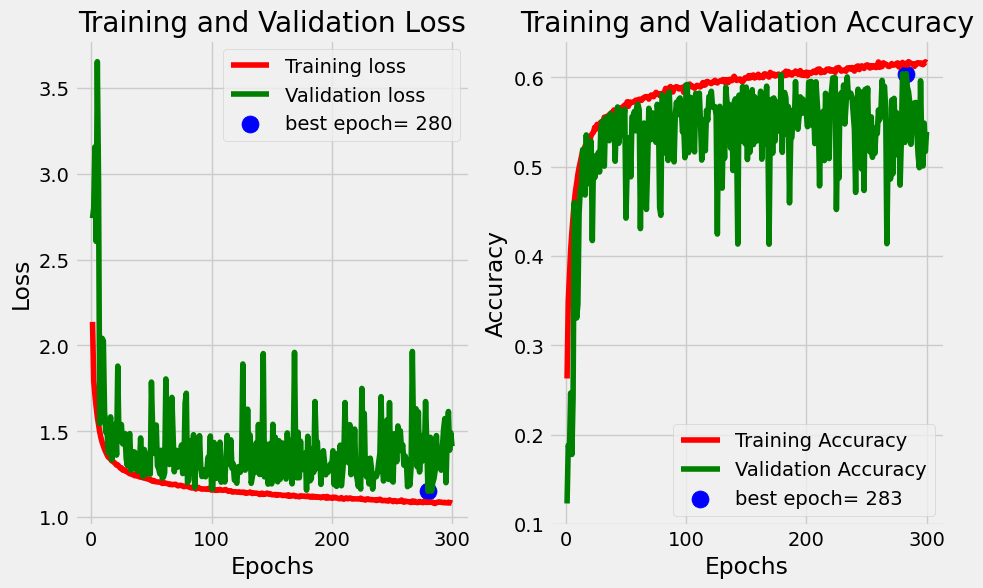

In [150]:
# adapted after: https://www.kaggle.com/code/youssefabdelghfar/brain-tumor-using-efficientnetb3
print(rep)
from matplotlib import pyplot as plt
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
Epochs = [i+1 for i in range(len(tr_acc))]
loss_label = f'best epoch= {str(index_loss + 1)}'
acc_label = f'best epoch= {str(index_acc + 1)}'

# Plot training history
plt.figure(figsize= (10, 6))  # 
plt.style.use('fivethirtyeight')

plt.subplot(1, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


#plt.subplots_adjust(hspace=0.4)

plt.tight_layout
plt.show()

# 3.5 - Prediction for some random samples

Labeled class : 7.0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Recognized class  :  7


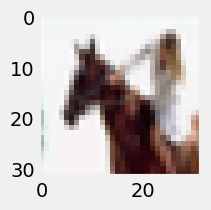

In [13]:

# Examples
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from keras.models import load_model
in_coding='clast'
out_coding='cat'

plt.figure(figsize = (2,2))
plt.grid(False)


if datagen==False:
    max_val=x_test.max()
    selectia=int(np.shape(x_test)[0]*np.random.rand(1)[0])  #
    img1=x_test[selectia,:,:,:]/max_val
    if np.shape(x_train)[3]==1:
      plt.imshow(img1[:,:,0],cmap='gray')
    elif np.shape(x_train)[3]==3:
      plt.imshow(img1)
    if out_coding=='cat':
        label=np.dot(y_test[selectia,:],1+np.array(range(num_classes)).T)
    elif out_coding=='non':
        label=y_test[selectia]
    print('Labeled class :', label-1)
    z=model.predict(x_test[selectia:selectia+1,:,:,:])
    print('Recognized class  : ',np.argmax(z))
else:
    for x_test,y_test in validation_generator: # test_generator: #
        break;

    selectia=int(sbatch_size*np.random.rand(1)[0])  #
    if in_coding=='cfirst':    # Cazul utilizari mediului Pytorch
        max_val=np.max(x_test)
        img1=x_test[selectia,:,:,:]/max_val
        img2=img1.permute(1, 2, 0).numpy()
        if np.shape(x_test)[1]==1:
          plt.imshow(img2[:,:,0],cmap='gray')
        elif np.shape(x_test)[1]==3:
          plt.imshow(img2)
    elif in_coding=='clast':
        max_val=np.max(x_test)
        img1=x_test[selectia,:,:,:]/max_val
        if np.shape(x_test)[3]==1:
          plt.imshow(img1[:,:,0],cmap='gray')
        elif np.shape(x_test)[3]==3:
          plt.imshow(img1)


    if out_coding=='cat':
            #labels=(np.dot(j,np.array(range(num_classes)).T)).astype('int16')
            label=np.dot(y_test[selectia,:],1+np.array(range(num_classes)).T)
    elif out_coding=='non':
            labels=y_test[selectia]
    print('Labeled class :', label-1)
    z=model.predict(x_test[selectia:selectia+1,:,:,:])
    print('Recognized class  : ',np.argmax(z))
